<a href="https://colab.research.google.com/github/narumirr/Visi-Komputer/blob/main/JS05_DL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# JOBSHEET 05 DL: Teknik Segmentasi Gambar 1 (Segmentasi Semantik Berbasis Deep Learning)
Mata kuliah Visi Komputer, Politeknik Negeri Semarang. Dosen: Ir. Prayitno, S.ST., M.T., Ph.D.

Notebook ini berisi enam praktikum (D1 sampai D6):
D1 menyiapkan data Oxford-IIIT Pet, D2 melatih U-Net dari nol, D3 menghitung metrik IoU/Dice/mIoU,
D4 transfer learning DeepLabV3, D5 fine-tuning SegFormer, D6 analisis kesalahan.

**Cara pakai di Google Colab:** Runtime > Change runtime type > T4 GPU, lalu Runtime > Run all.

| Bagian | Perkiraan waktu Colab T4 (mode PENUH) | Waktu nyata di CPU box (mode CEPAT) |
|---|---|---|
| Instalasi + unduh subset data | 3 sampai 8 menit (bergantung kecepatan server VGG) | lihat output sel |
| D2 U-Net dari nol | sekitar 5 menit | lihat output sel |
| D4 DeepLabV3 | sekitar 4 menit | lihat output sel |
| D5 SegFormer-B0 | sekitar 4 menit | lihat output sel |
| D3 dan D6 evaluasi | kurang dari 2 menit | lihat output sel |

Perkiraan waktu Colab adalah estimasi, bukan hasil pengukuran. Notebook otomatis memakai mode CEPAT
(resolusi dan jumlah data lebih kecil) bila GPU tidak tersedia.

In [1]:
# === Persiapan 1: instalasi pustaka (Colab sudah memiliki torch dan torchvision) ===
%pip install -q transformers

In [2]:
# === Persiapan 2: impor, cek GPU, seed, dan konfigurasi ===
import os, time, random, json
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision

def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
set_seed(42)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
CEPAT = DEVICE == "cpu"   # tanpa GPU: jalankan versi diperkecil
print("PyTorch", torch.__version__, "| torchvision", torchvision.__version__)
print("Perangkat:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU saja")

CFG = dict(
    IMG     = 128 if CEPAT else 256,   # ukuran sisi citra (piksel)
    N_TRAIN = 320 if CEPAT else 2000,  # jumlah citra latih (dari daftar trainval resmi)
    N_TEST  = 100 if CEPAT else 500,   # jumlah citra uji (dari daftar test resmi)
    BATCH   = 16,
    EP_UNET = 6 if CEPAT else 15,
    EP_DLV3 = 2 if CEPAT else 6,
    EP_SEGF = 3 if CEPAT else 6,
    BASE_CH = 16 if CEPAT else 32,     # lebar kanal U-Net
)
print("Mode:", "CEPAT (CPU)" if CEPAT else "PENUH (GPU)", CFG)
FIG_DIR = "figures"; os.makedirs(FIG_DIR, exist_ok=True)
WAKTU = {}   # catatan waktu tiap bagian

PyTorch 2.11.0+cu130 | torchvision 0.26.0+cu130
Perangkat: cuda | Tesla T4
Mode: PENUH (GPU) {'IMG': 256, 'N_TRAIN': 2000, 'N_TEST': 500, 'BATCH': 16, 'EP_UNET': 15, 'EP_DLV3': 6, 'EP_SEGF': 6, 'BASE_CH': 32}


## Praktikum D1: Mengenal Data Segmentasi (Oxford-IIIT Pet)
Dataset: **Oxford-IIIT Pet** (Parkhi dkk., 2012), 37 ras kucing dan anjing, 7.349 citra dengan anotasi *trimap* per piksel.
Lisensi: Creative Commons Attribution-ShareAlike 4.0 (CC BY-SA 4.0), hak cipta foto tetap pada pemilik aslinya.
Sumber resmi: https://www.robots.ox.ac.uk/~vgg/data/pets/

Nilai trimap: 1 = hewan, 2 = latar, 3 = batas (piksel ragu-ragu). Kita ubah menjadi masker biner
(1 = hewan, 0 = latar) dan menandai piksel batas sebagai *diabaikan* saat menghitung loss dan metrik.
Agar cepat, kita mengunduh **subset** secara streaming dari arsip resmi (urutan file di arsip sudah acak).

In [3]:
# === D1.1 Unduh subset Oxford-IIIT Pet langsung dari server resmi VGG ===
import tarfile, urllib.request
URL_IMG = "https://thor.robots.ox.ac.uk/pets/images.tar.gz"
URL_ANN = "https://thor.robots.ox.ac.uk/pets/annotations.tar.gz"

def ambil_subset_pet(root="data/pet_subset", n_train=480, n_test=120):
    os.makedirs(f"{root}/images", exist_ok=True); os.makedirs(f"{root}/trimaps", exist_ok=True)
    ann = f"{root}/annotations.tar.gz"
    if not os.path.exists(ann):
        urllib.request.urlretrieve(URL_ANN, ann)
    split, trimaps = {}, {}
    with tarfile.open(ann, "r:gz") as t:
        for m in t:
            if m.name.endswith("annotations/trainval.txt") or m.name.endswith("annotations/test.txt"):
                s = "train" if "trainval" in m.name else "test"
                for line in t.extractfile(m).read().decode().splitlines():
                    if line.strip():
                        split[line.split()[0]] = s
            elif "/trimaps/" in m.name and m.name.endswith(".png") and "._" not in m.name:
                trimaps[os.path.basename(m.name)[:-4]] = t.extractfile(m).read()
    def hitung():
        ada = [f[:-4] for f in os.listdir(f"{root}/images") if f.endswith(".jpg")]
        return (sorted(i for i in ada if split.get(i) == "train"),
                sorted(i for i in ada if split.get(i) == "test"))
    tr, te = hitung()
    if len(tr) >= n_train and len(te) >= n_test:
        print("Subset sudah tersedia di", root)
        return tr[:n_train], te[:n_test]
    with urllib.request.urlopen(URL_IMG) as resp, tarfile.open(fileobj=resp, mode="r|gz") as t:
        for m in t:
            nama = os.path.basename(m.name)
            if not nama.endswith(".jpg"):
                continue
            iid = nama[:-4]; s = split.get(iid)
            if iid not in trimaps or s is None:
                continue
            if (s == "train" and len(tr) >= n_train) or (s == "test" and len(te) >= n_test):
                continue
            with open(f"{root}/images/{nama}", "wb") as f: f.write(t.extractfile(m).read())
            with open(f"{root}/trimaps/{iid}.png", "wb") as f: f.write(trimaps[iid])
            (tr if s == "train" else te).append(iid)
            if len(tr) >= n_train and len(te) >= n_test:
                break
    tr, te = hitung()
    return tr[:n_train], te[:n_test]

t0 = time.time()
ROOT = "data/pet_subset"
ID_TRAIN, ID_TEST = ambil_subset_pet(ROOT, CFG["N_TRAIN"], CFG["N_TEST"])
print(f"Citra latih: {len(ID_TRAIN)} | citra uji: {len(ID_TEST)} | waktu {time.time()-t0:.1f} detik")
print("Jumlah ras pada data latih:", len({i.rsplit('_', 1)[0] for i in ID_TRAIN}))

Citra latih: 2000 | citra uji: 500 | waktu 19.1 detik
Jumlah ras pada data latih: 37


In [4]:
# === D1.2 Dataset PyTorch: citra RGB + masker biner + masker valid ===
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

def muat_pasangan(iid, size):
    img = Image.open(f"{ROOT}/images/{iid}.jpg").convert("RGB").resize((size, size), Image.BILINEAR)
    tri = Image.open(f"{ROOT}/trimaps/{iid}.png").resize((size, size), Image.NEAREST)
    return np.array(img), np.array(tri)

class PetSegDataset(torch.utils.data.Dataset):
    # Semua data dimuat sekali ke memori dalam bentuk uint8 agar pelatihan cepat
    def __init__(self, ids, size, augment=False):
        pairs = [muat_pasangan(i, size) for i in ids]
        self.img = torch.from_numpy(np.stack([p[0] for p in pairs])).permute(0, 3, 1, 2)  # (N,3,H,W) uint8
        self.tri = torch.from_numpy(np.stack([p[1] for p in pairs]))                      # (N,H,W)   uint8
        self.augment = augment
    def __len__(self):
        return len(self.img)
    def __getitem__(self, i):
        x = self.img[i].float() / 255.0
        tri = self.tri[i]
        y = (tri == 1).float().unsqueeze(0)        # 1 = hewan, 0 = latar
        valid = (tri != 3).float().unsqueeze(0)    # 0 pada piksel batas (diabaikan)
        if self.augment and random.random() < 0.5:  # augmentasi: flip horizontal
            x, y, valid = x.flip(-1), y.flip(-1), valid.flip(-1)
        return (x - MEAN) / STD, y, valid

t0 = time.time()
ds_train = PetSegDataset(ID_TRAIN, CFG["IMG"], augment=True)
ds_test  = PetSegDataset(ID_TEST,  CFG["IMG"], augment=False)
dl_train = torch.utils.data.DataLoader(ds_train, batch_size=CFG["BATCH"], shuffle=True)
dl_test  = torch.utils.data.DataLoader(ds_test,  batch_size=CFG["BATCH"], shuffle=False)
x, y, v = ds_train[0]
print("Bentuk x:", tuple(x.shape), "| y:", tuple(y.shape), "| valid:", tuple(v.shape))
tri_all = ds_train.tri
print("Proporsi piksel  hewan: %.3f | latar: %.3f | batas: %.3f" % tuple(((tri_all == k).float().mean().item()) for k in (1, 2, 3)))
WAKTU["D1 data"] = time.time() - t0

Bentuk x: (3, 256, 256) | y: (1, 256, 256) | valid: (1, 256, 256)
Proporsi piksel  hewan: 0.301 | latar: 0.584 | batas: 0.114


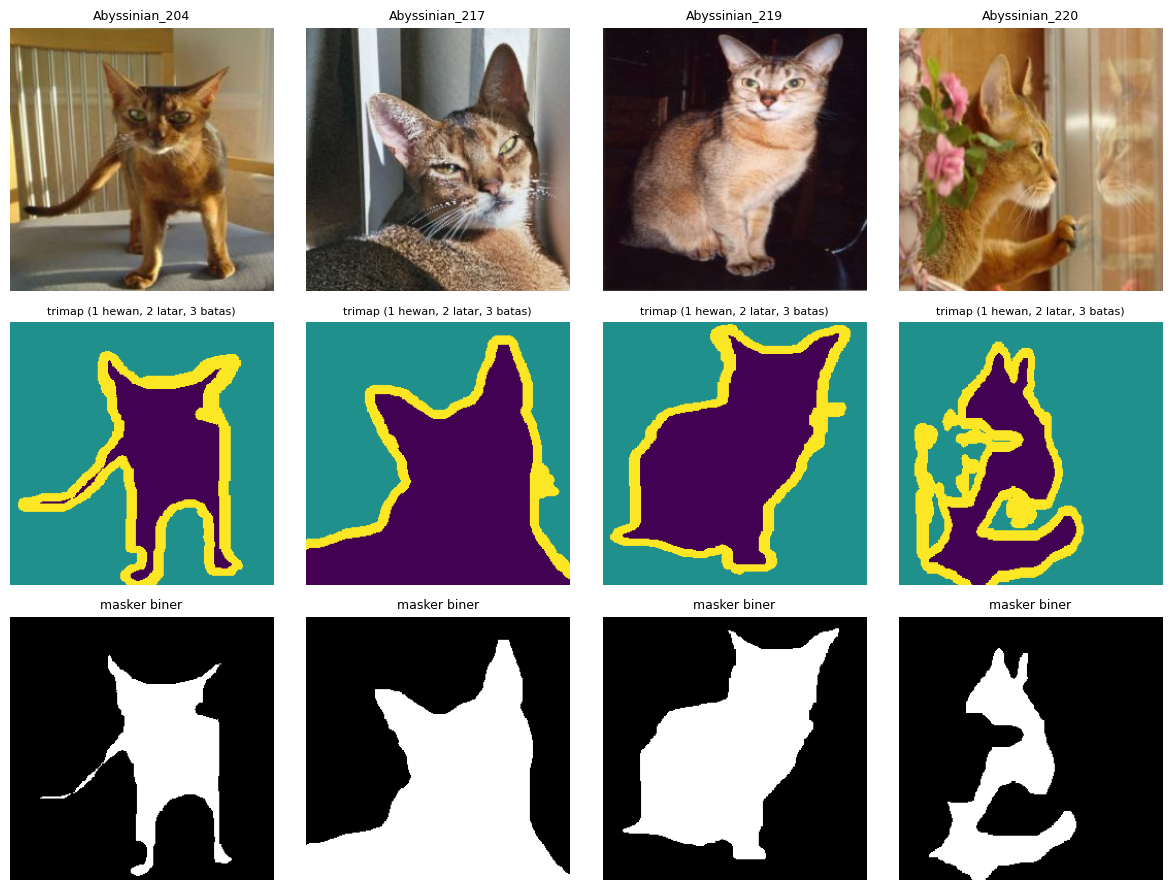

In [5]:
# === D1.3 Visualisasi: citra, trimap, dan masker biner ===
def denorm(x):
    return (x * STD + MEAN).clamp(0, 1).permute(1, 2, 0).numpy()

fig, ax = plt.subplots(3, 4, figsize=(12, 9))
for k in range(4):
    x, y, v = ds_test[k]
    ax[0, k].imshow(denorm(x)); ax[0, k].set_title(ID_TEST[k], fontsize=9)
    ax[1, k].imshow(ds_test.tri[k], cmap="viridis", vmin=1, vmax=3); ax[1, k].set_title("trimap (1 hewan, 2 latar, 3 batas)", fontsize=8)
    ax[2, k].imshow(y[0], cmap="gray"); ax[2, k].set_title("masker biner", fontsize=9)
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/js05_d1_contoh_data.png", dpi=120); plt.show()

**Tugas kecil D1:** Hitung proporsi piksel hewan, latar, dan batas pada data uji. Mengapa piksel batas lebih baik diabaikan daripada dipaksa menjadi salah satu kelas?

## Praktikum D2: Membangun dan Melatih U-Net dari Nol
U-Net (Ronneberger dkk., 2015) terdiri dari *encoder* (mengecilkan resolusi, menangkap konteks), *decoder*
(memperbesar kembali), dan *skip connection* yang menyalurkan detail tepi dari encoder ke decoder.
Loss yang dipakai: gabungan **BCE** (per piksel) dan **Dice loss** (tumpang tindih wilayah), keduanya hanya pada piksel valid.

In [6]:
# === D2.1 Arsitektur U-Net kecil ===
class DoubleConv(nn.Sequential):
    def __init__(self, cin, cout):
        super().__init__(
            nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
            nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True))

class UNet(nn.Module):
    def __init__(self, in_ch=3, out_ch=1, base=16):
        super().__init__()
        c = [base, base*2, base*4, base*8, base*16]
        self.enc = nn.ModuleList([DoubleConv(in_ch, c[0])] + [DoubleConv(c[i], c[i+1]) for i in range(4)])
        self.up  = nn.ModuleList([nn.ConvTranspose2d(c[i+1], c[i], 2, stride=2) for i in reversed(range(4))])
        self.dec = nn.ModuleList([DoubleConv(c[i]*2, c[i]) for i in reversed(range(4))])
        self.head = nn.Conv2d(c[0], out_ch, 1)
    def forward(self, x):
        skips = []
        for i, blk in enumerate(self.enc):
            x = blk(x if i == 0 else F.max_pool2d(x, 2))
            skips.append(x)
        x = skips.pop()                       # bottleneck
        for up, dec in zip(self.up, self.dec):
            x = up(x)
            x = dec(torch.cat([x, skips.pop()], dim=1))   # skip connection
        return self.head(x)                   # logit (B,1,H,W)

unet = UNet(base=CFG["BASE_CH"]).to(DEVICE)
print("Jumlah parameter U-Net: %.2f juta" % (sum(p.numel() for p in unet.parameters()) / 1e6))
print("Uji bentuk keluaran:", tuple(unet(torch.zeros(2, 3, CFG["IMG"], CFG["IMG"], device=DEVICE)).shape))

Jumlah parameter U-Net: 7.76 juta
Uji bentuk keluaran: (2, 1, 256, 256)


In [7]:
# === D2.2 Loss BCE + Dice dengan masker valid, dan fungsi pelatihan umum ===
def bce_dice_loss(logit, y, valid, w_dice=1.0, eps=1.0):
    bce = F.binary_cross_entropy_with_logits(logit, y, reduction="none")
    bce = (bce * valid).sum() / valid.sum().clamp_min(1)
    p = torch.sigmoid(logit) * valid
    inter = (p * y * valid).sum(dim=(1, 2, 3))
    dice = 1 - (2 * inter + eps) / (p.sum(dim=(1, 2, 3)) + (y * valid).sum(dim=(1, 2, 3)) + eps)
    return bce + w_dice * dice.mean()

def latih(model, forward, epochs, lr, nama, param_groups=None):
    opt = torch.optim.AdamW(param_groups or model.parameters(), lr=lr, weight_decay=1e-4)
    riwayat = {"train": [], "test": []}
    t0 = time.time()
    for ep in range(epochs):
        model.train(); tot = 0
        for x, y, v in dl_train:
            x, y, v = x.to(DEVICE), y.to(DEVICE), v.to(DEVICE)
            loss = bce_dice_loss(forward(model, x), y, v)
            opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item() * len(x)
        model.eval(); tot_te = 0
        with torch.no_grad():
            for x, y, v in dl_test:
                x, y, v = x.to(DEVICE), y.to(DEVICE), v.to(DEVICE)
                tot_te += bce_dice_loss(forward(model, x), y, v).item() * len(x)
        riwayat["train"].append(tot / len(ds_train)); riwayat["test"].append(tot_te / len(ds_test))
        print(f"[{nama}] epoch {ep+1}/{epochs}  loss latih {riwayat['train'][-1]:.4f}  loss uji {riwayat['test'][-1]:.4f}  ({time.time()-t0:.0f} s)")
    WAKTU[nama] = time.time() - t0
    return riwayat

fwd_unet = lambda m, x: m(x)
set_seed(42)
hist_unet = latih(unet, fwd_unet, CFG["EP_UNET"], 1e-3, "U-Net (dari nol)")

[U-Net (dari nol)] epoch 1/15  loss latih 0.9097  loss uji 0.7724  (47 s)
[U-Net (dari nol)] epoch 2/15  loss latih 0.7252  loss uji 0.7092  (100 s)
[U-Net (dari nol)] epoch 3/15  loss latih 0.6294  loss uji 0.6240  (154 s)
[U-Net (dari nol)] epoch 4/15  loss latih 0.5716  loss uji 0.5620  (207 s)
[U-Net (dari nol)] epoch 5/15  loss latih 0.5288  loss uji 0.4890  (260 s)
[U-Net (dari nol)] epoch 6/15  loss latih 0.4712  loss uji 0.4387  (312 s)
[U-Net (dari nol)] epoch 7/15  loss latih 0.4432  loss uji 0.5580  (365 s)
[U-Net (dari nol)] epoch 8/15  loss latih 0.4050  loss uji 0.4252  (418 s)
[U-Net (dari nol)] epoch 9/15  loss latih 0.3893  loss uji 0.3853  (471 s)
[U-Net (dari nol)] epoch 10/15  loss latih 0.3734  loss uji 0.3768  (524 s)
[U-Net (dari nol)] epoch 11/15  loss latih 0.3462  loss uji 0.3542  (577 s)
[U-Net (dari nol)] epoch 12/15  loss latih 0.3290  loss uji 0.3301  (629 s)
[U-Net (dari nol)] epoch 13/15  loss latih 0.3160  loss uji 0.4164  (682 s)
[U-Net (dari nol)] epo

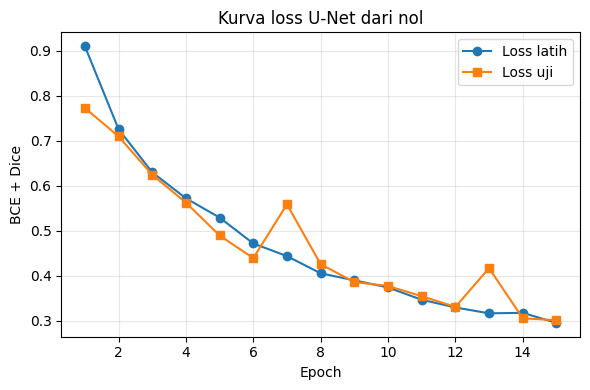

In [8]:
# === D2.3 Kurva loss U-Net ===
plt.figure(figsize=(6, 4))
ep = range(1, len(hist_unet["train"]) + 1)
plt.plot(ep, hist_unet["train"], "o-", label="Loss latih")
plt.plot(ep, hist_unet["test"], "s-", label="Loss uji")
plt.xlabel("Epoch"); plt.ylabel("BCE + Dice"); plt.title("Kurva loss U-Net dari nol"); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/js05_d2_kurva_unet.png", dpi=120); plt.show()

**Tugas kecil D2:** Ganti `w_dice=0` (hanya BCE) lalu latih ulang. Bandingkan nilai IoU pada D3. Kapan Dice loss lebih membantu?

## Praktikum D3: Metrik Evaluasi Segmentasi (IoU, Dice, Pixel Accuracy, mIoU)
Untuk kelas hewan: IoU = TP / (TP + FP + FN), Dice = 2TP / (2TP + FP + FN), Pixel Accuracy = piksel benar / piksel valid.
mIoU = rata-rata IoU kelas hewan dan kelas latar. Piksel batas tidak dihitung.

In [9]:
# === D3.1 Fungsi metrik dan evaluasi ===
@torch.no_grad()
def evaluasi(model, forward, thr=0.5):
    model.eval()
    TP = FP = FN = TN = 0; iou_per_citra = []
    for x, y, v in dl_test:
        x, y, v = x.to(DEVICE), y.to(DEVICE), v.to(DEVICE)
        pred = (torch.sigmoid(forward(model, x)) > thr).float()
        tp = (pred * y * v).sum(dim=(1, 2, 3)); fp = (pred * (1 - y) * v).sum(dim=(1, 2, 3))
        fn = ((1 - pred) * y * v).sum(dim=(1, 2, 3)); tn = ((1 - pred) * (1 - y) * v).sum(dim=(1, 2, 3))
        TP += tp.sum().item(); FP += fp.sum().item(); FN += fn.sum().item(); TN += tn.sum().item()
        iou_per_citra += (tp / (tp + fp + fn).clamp_min(1)).tolist()
    iou_fg = TP / (TP + FP + FN); iou_bg = TN / (TN + FN + FP)
    return {"IoU_hewan": iou_fg, "IoU_latar": iou_bg, "mIoU": (iou_fg + iou_bg) / 2,
            "Dice": 2 * TP / (2 * TP + FP + FN), "PixelAcc": (TP + TN) / (TP + TN + FP + FN),
            "iou_per_citra": iou_per_citra}

def ringkas(m):
    return {k: round(v, 4) for k, v in m.items() if k != "iou_per_citra"}

HASIL = {}
HASIL["U-Net (dari nol)"] = evaluasi(unet, fwd_unet)
print(ringkas(HASIL["U-Net (dari nol)"]))

{'IoU_hewan': 0.8295, 'IoU_latar': 0.9053, 'mIoU': 0.8674, 'Dice': 0.9068, 'PixelAcc': 0.9352}


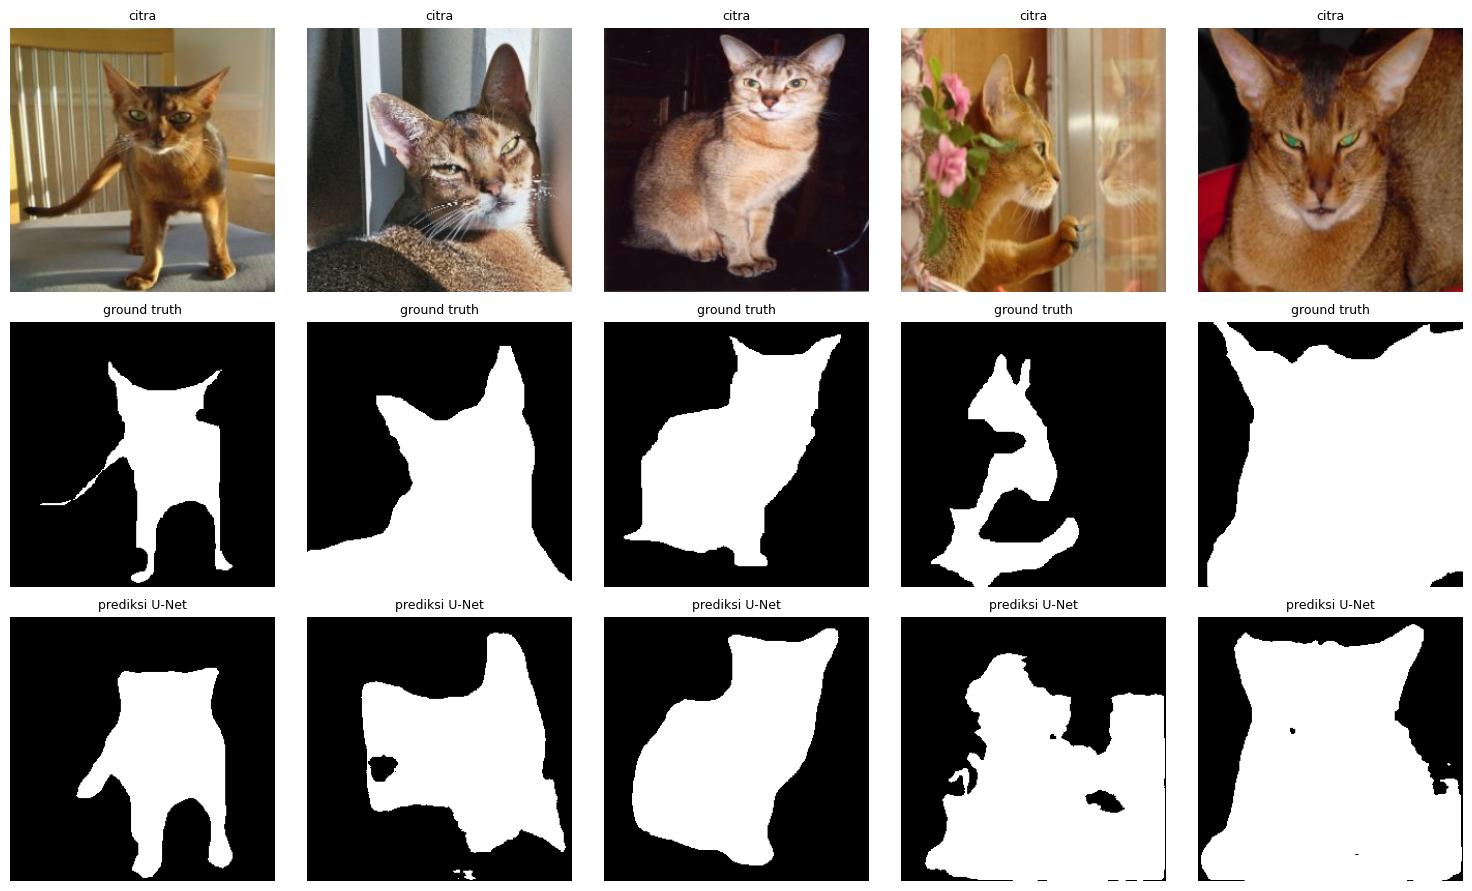

In [10]:
# === D3.2 Visualisasi prediksi U-Net ===
@torch.no_grad()
def prediksi(model, forward, idx):
    x = torch.stack([ds_test[i][0] for i in idx]).to(DEVICE)
    return (torch.sigmoid(forward(model, x)) > 0.5).float().cpu()

idx_vis = [0, 1, 2, 3, 4]
p_unet = prediksi(unet, fwd_unet, idx_vis)
fig, ax = plt.subplots(3, len(idx_vis), figsize=(3 * len(idx_vis), 9))
for j, i in enumerate(idx_vis):
    x, y, v = ds_test[i]
    ax[0, j].imshow(denorm(x)); ax[0, j].set_title("citra", fontsize=9)
    ax[1, j].imshow(y[0], cmap="gray"); ax[1, j].set_title("ground truth", fontsize=9)
    ax[2, j].imshow(p_unet[j, 0], cmap="gray"); ax[2, j].set_title("prediksi U-Net", fontsize=9)
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/js05_d3_prediksi_unet.png", dpi=120); plt.show()

**Tugas kecil D3:** Ubah ambang `thr` dari 0,5 menjadi 0,3 dan 0,7. Bagaimana pengaruhnya terhadap IoU dan Dice?

## Praktikum D4: Transfer Learning dengan DeepLabV3 (torchvision)
DeepLabV3 (Chen dkk., 2017) memakai *atrous convolution* dan modul ASPP untuk menangkap konteks multi-skala.
Kita memakai varian ringan **DeepLabV3-MobileNetV3-Large** dengan bobot pra-latih dari torchvision,
lalu mengganti lapisan klasifikasi terakhir menjadi 1 kanal (hewan vs latar).

In [11]:
# === D4.1 Muat DeepLabV3 pra-latih dan ganti kepala klasifikasi ===
from torchvision.models.segmentation import deeplabv3_mobilenet_v3_large, DeepLabV3_MobileNet_V3_Large_Weights
set_seed(42)
dlv3 = deeplabv3_mobilenet_v3_large(weights=DeepLabV3_MobileNet_V3_Large_Weights.DEFAULT)
dlv3.classifier[4] = nn.Conv2d(256, 1, kernel_size=1)   # 21 kelas VOC -> 1 kanal
dlv3.aux_classifier = None
dlv3 = dlv3.to(DEVICE)
print("Jumlah parameter DeepLabV3-MobileNetV3: %.2f juta" % (sum(p.numel() for p in dlv3.parameters()) / 1e6))
fwd_dlv3 = lambda m, x: m(x)["out"]
groups = [{"params": dlv3.backbone.parameters(), "lr": 1e-4},     # backbone: lr kecil
          {"params": dlv3.classifier.parameters(), "lr": 1e-3}]   # kepala baru: lr besar
hist_dlv3 = latih(dlv3, fwd_dlv3, CFG["EP_DLV3"], 1e-3, "DeepLabV3-MobileNetV3 (pra-latih)", param_groups=groups)
HASIL["DeepLabV3-MobileNetV3 (pra-latih)"] = evaluasi(dlv3, fwd_dlv3)
print(ringkas(HASIL["DeepLabV3-MobileNetV3 (pra-latih)"]))

Downloading: "https://download.pytorch.org/models/deeplabv3_mobilenet_v3_large-fc3c493d.pth" to /root/.cache/torch/hub/checkpoints/deeplabv3_mobilenet_v3_large-fc3c493d.pth


100%|██████████| 42.3M/42.3M [00:00<00:00, 158MB/s]


Jumlah parameter DeepLabV3-MobileNetV3: 11.02 juta
[DeepLabV3-MobileNetV3 (pra-latih)] epoch 1/6  loss latih 0.1819  loss uji 0.1292  (24 s)
[DeepLabV3-MobileNetV3 (pra-latih)] epoch 2/6  loss latih 0.0925  loss uji 0.1254  (47 s)
[DeepLabV3-MobileNetV3 (pra-latih)] epoch 3/6  loss latih 0.0717  loss uji 0.1028  (71 s)
[DeepLabV3-MobileNetV3 (pra-latih)] epoch 4/6  loss latih 0.0589  loss uji 0.1056  (94 s)
[DeepLabV3-MobileNetV3 (pra-latih)] epoch 5/6  loss latih 0.0526  loss uji 0.1113  (118 s)
[DeepLabV3-MobileNetV3 (pra-latih)] epoch 6/6  loss latih 0.0446  loss uji 0.1033  (142 s)
{'IoU_hewan': 0.9532, 'IoU_latar': 0.9751, 'mIoU': 0.9642, 'Dice': 0.9761, 'PixelAcc': 0.9835}


**Tugas kecil D4:** Bekukan backbone (`requires_grad=False`) dan latih hanya kepala klasifikasi. Bandingkan waktu dan mIoU.

## Praktikum D5: Fine-Tuning SegFormer-B0 (Hugging Face Transformers)
SegFormer (Xie dkk., 2021) memakai encoder Transformer hierarkis (Mix Transformer) dan decoder MLP ringan.
Kita memakai encoder **nvidia/mit-b0** (pra-latih ImageNet-1K). Catatan lisensi: bobot SegFormer dari NVIDIA berlisensi
NVIDIA Source Code License, hanya untuk penggunaan nonkomersial (riset atau evaluasi), cukup untuk keperluan kuliah.

In [12]:
# === D5.1 Muat SegFormer-B0 dan latih ===
import transformers
from transformers import SegformerForSemanticSegmentation
transformers.logging.set_verbosity_error()
set_seed(42)
segf = SegformerForSemanticSegmentation.from_pretrained("nvidia/mit-b0", num_labels=1).to(DEVICE)
print("Jumlah parameter SegFormer-B0: %.2f juta" % (sum(p.numel() for p in segf.parameters()) / 1e6))

def fwd_segf(m, x):
    logit = m(pixel_values=x).logits                       # resolusi 1/4 dari input
    return F.interpolate(logit, size=x.shape[-2:], mode="bilinear", align_corners=False)

hist_segf = latih(segf, fwd_segf, CFG["EP_SEGF"], 3e-4, "SegFormer-B0 (pra-latih)")
HASIL["SegFormer-B0 (pra-latih)"] = evaluasi(segf, fwd_segf)
print(ringkas(HASIL["SegFormer-B0 (pra-latih)"]))

config.json:   0%|          | 0.00/70.0k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 14.4MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/192 [00:00<?, ?it/s]

Jumlah parameter SegFormer-B0: 3.71 juta


model.safetensors: reconstructing file:   0%|          |  0.00B / 14.3MB            

model.safetensors: downloading bytes:           |  0.00B            

[SegFormer-B0 (pra-latih)] epoch 1/6  loss latih 0.3124  loss uji 0.1523  (29 s)
[SegFormer-B0 (pra-latih)] epoch 2/6  loss latih 0.1480  loss uji 0.1201  (58 s)
[SegFormer-B0 (pra-latih)] epoch 3/6  loss latih 0.0977  loss uji 0.1168  (85 s)
[SegFormer-B0 (pra-latih)] epoch 4/6  loss latih 0.0846  loss uji 0.1015  (113 s)
[SegFormer-B0 (pra-latih)] epoch 5/6  loss latih 0.0653  loss uji 0.1104  (141 s)
[SegFormer-B0 (pra-latih)] epoch 6/6  loss latih 0.0672  loss uji 0.1121  (169 s)
{'IoU_hewan': 0.9448, 'IoU_latar': 0.9702, 'mIoU': 0.9575, 'Dice': 0.9716, 'PixelAcc': 0.9803}


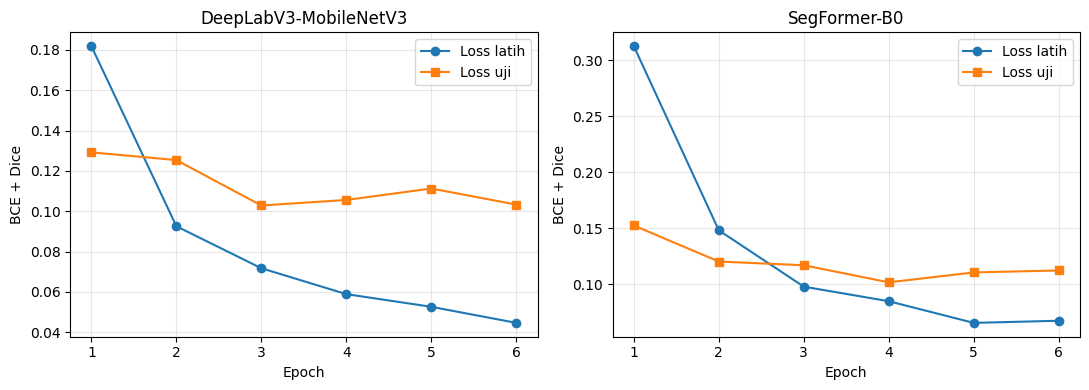

In [13]:
# === D5.2 Kurva loss model pra-latih ===
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, (nama, h) in zip(ax, [("DeepLabV3-MobileNetV3", hist_dlv3), ("SegFormer-B0", hist_segf)]):
    ep = range(1, len(h["train"]) + 1)
    a.plot(ep, h["train"], "o-", label="Loss latih"); a.plot(ep, h["test"], "s-", label="Loss uji")
    a.set_title(nama); a.set_xlabel("Epoch"); a.set_ylabel("BCE + Dice"); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/js05_d5_kurva_pralatih.png", dpi=120); plt.show()

**Tugas kecil D5:** Ganti `nvidia/mit-b0` dengan `nvidia/mit-b1` (lebih besar). Catat jumlah parameter, waktu per epoch, dan mIoU.

## Praktikum D6: Perbandingan Model dan Analisis Kesalahan
Kita bandingkan ketiga model, lalu melihat citra dengan IoU terendah. Peta kesalahan: hijau = benar hewan (TP),
merah = latar yang diprediksi hewan (FP), biru = hewan yang terlewat (FN).

In [14]:
# === D6.1 Tabel perbandingan ===
import pandas as pd
param = {"U-Net (dari nol)": unet, "DeepLabV3-MobileNetV3 (pra-latih)": dlv3, "SegFormer-B0 (pra-latih)": segf}
tabel = pd.DataFrame([{"Model": k, **ringkas(v), "Parameter (juta)": round(sum(p.numel() for p in param[k].parameters()) / 1e6, 2),
                       "Waktu latih (s)": round(WAKTU[k], 1)} for k, v in HASIL.items()])
print(tabel.to_string(index=False))
tabel.to_csv(f"{FIG_DIR}/js05_tabel_hasil.csv", index=False)
with open(f"{FIG_DIR}/js05_hasil.json", "w") as f:
    json.dump({"perangkat": DEVICE, "mode": "CEPAT" if CEPAT else "PENUH", "cfg": CFG,
               "hasil": {k: ringkas(v) for k, v in HASIL.items()}, "waktu_detik": WAKTU}, f, indent=2)

                            Model  IoU_hewan  IoU_latar   mIoU   Dice  PixelAcc  Parameter (juta)  Waktu latih (s)
                 U-Net (dari nol)     0.8295     0.9053 0.8674 0.9068    0.9352              7.76            787.3
DeepLabV3-MobileNetV3 (pra-latih)     0.9532     0.9751 0.9642 0.9761    0.9835             11.02            141.5
         SegFormer-B0 (pra-latih)     0.9448     0.9702 0.9575 0.9716    0.9803              3.71            169.3


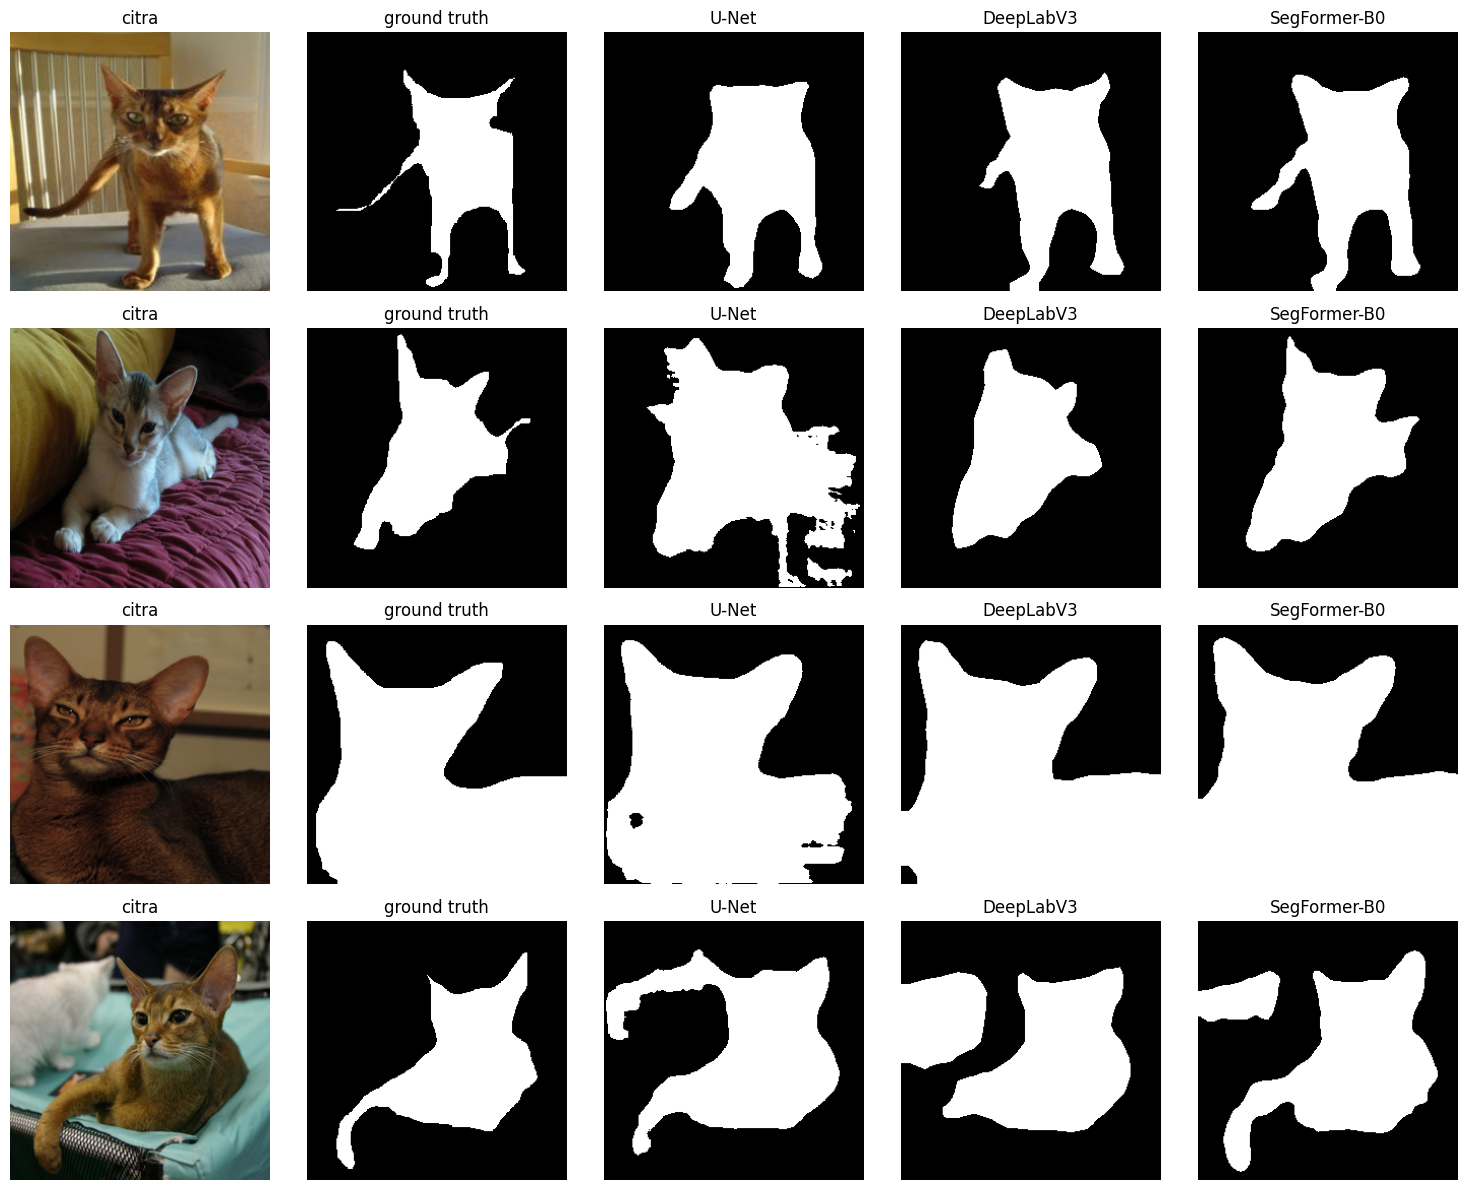

In [15]:
# === D6.2 Contoh prediksi ketiga model ===
model_fwd = [("U-Net", unet, fwd_unet), ("DeepLabV3", dlv3, fwd_dlv3), ("SegFormer-B0", segf, fwd_segf)]
idx_vis = [0, 5, 10, 15]
fig, ax = plt.subplots(len(idx_vis), 5, figsize=(15, 3 * len(idx_vis)))
preds = {n: prediksi(m, f, idx_vis) for n, m, f in model_fwd}
for r, i in enumerate(idx_vis):
    x, y, v = ds_test[i]
    ax[r, 0].imshow(denorm(x)); ax[r, 1].imshow(y[0], cmap="gray")
    ax[r, 0].set_title("citra"); ax[r, 1].set_title("ground truth")
    for c, (n, _, _) in enumerate(model_fwd):
        ax[r, c + 2].imshow(preds[n][r, 0], cmap="gray"); ax[r, c + 2].set_title(n)
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/js05_d6_perbandingan.png", dpi=110); plt.show()

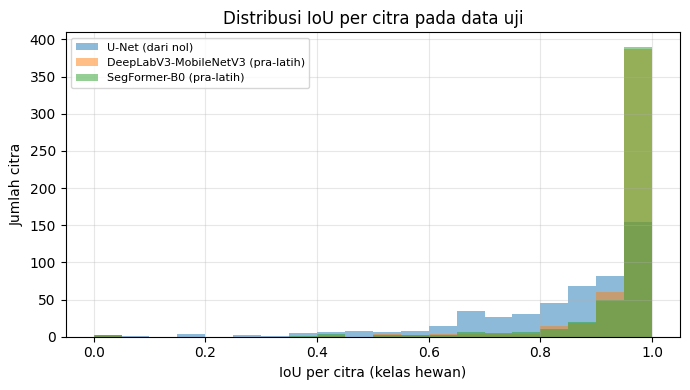

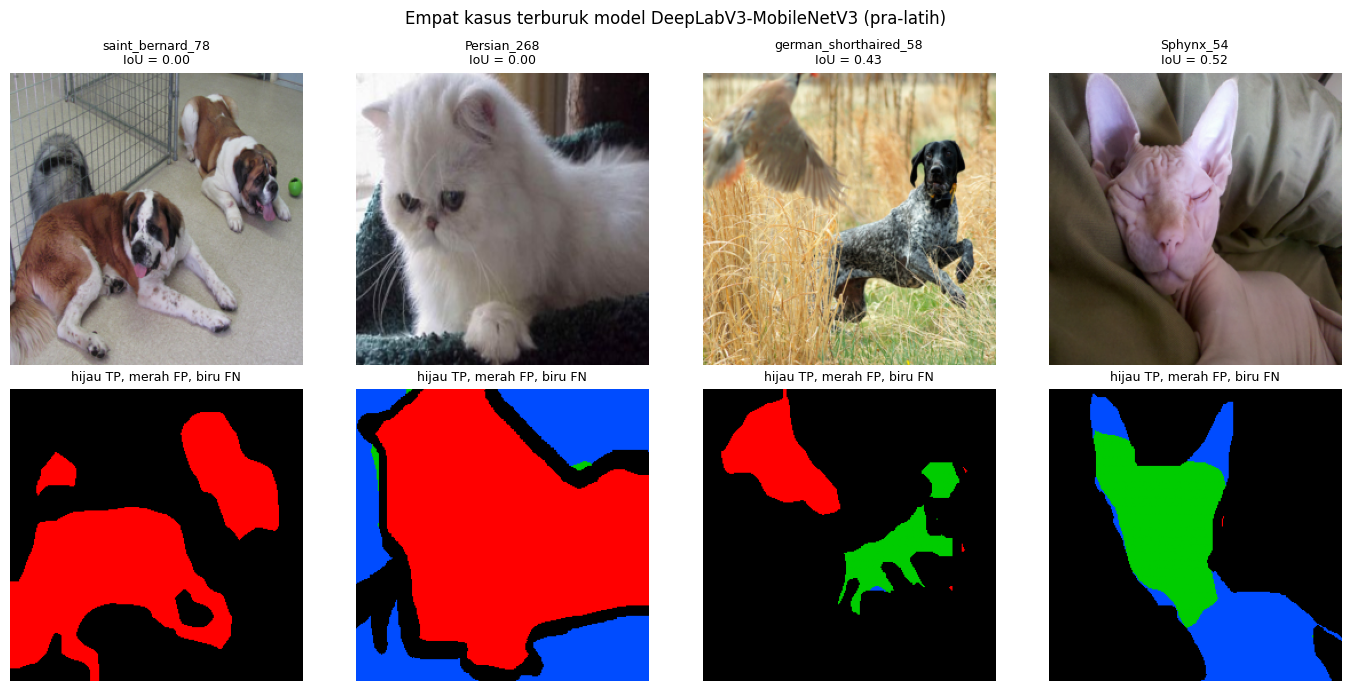

Model terbaik: DeepLabV3-MobileNetV3 (pra-latih) | IoU terendah: [0.0, 0.004, 0.426, 0.519]


In [16]:
# === D6.3 Analisis kesalahan: distribusi IoU per citra dan kasus terburuk ===
plt.figure(figsize=(7, 4))
for n, m in HASIL.items():
    plt.hist(m["iou_per_citra"], bins=20, range=(0, 1), alpha=.5, label=n)
plt.xlabel("IoU per citra (kelas hewan)"); plt.ylabel("Jumlah citra"); plt.legend(fontsize=8); plt.grid(alpha=.3)
plt.title("Distribusi IoU per citra pada data uji")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/js05_d6_histogram_iou.png", dpi=120); plt.show()

terbaik = max(HASIL, key=lambda k: HASIL[k]["mIoU"])
mdl, fw = {n: (m, f) for n, m, f in [("U-Net (dari nol)", unet, fwd_unet), ("DeepLabV3-MobileNetV3 (pra-latih)", dlv3, fwd_dlv3), ("SegFormer-B0 (pra-latih)", segf, fwd_segf)]}[terbaik]
iou = np.array(HASIL[terbaik]["iou_per_citra"]); buruk = np.argsort(iou)[:4].tolist()
pb = prediksi(mdl, fw, buruk)
fig, ax = plt.subplots(2, 4, figsize=(14, 7))
for j, i in enumerate(buruk):
    x, y, v = ds_test[i]; p = pb[j, 0]; g = y[0]; val = v[0]
    peta = np.zeros((*g.shape, 3))
    peta[((p == 1) & (g == 1) & (val == 1)).numpy()] = [0, .8, 0]
    peta[((p == 1) & (g == 0) & (val == 1)).numpy()] = [1, 0, 0]
    peta[((p == 0) & (g == 1) & (val == 1)).numpy()] = [0, .3, 1]
    ax[0, j].imshow(denorm(x)); ax[0, j].set_title(f"{ID_TEST[i]}\nIoU = {iou[i]:.2f}", fontsize=9)
    ax[1, j].imshow(peta); ax[1, j].set_title("hijau TP, merah FP, biru FN", fontsize=9)
for a in ax.ravel(): a.axis("off")
plt.suptitle(f"Empat kasus terburuk model {terbaik}")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/js05_d6_kasus_terburuk.png", dpi=110); plt.show()
print("Model terbaik:", terbaik, "| IoU terendah:", np.round(iou[buruk], 3).tolist())

In [17]:
# === D6.4 Ringkasan waktu tiap bagian ===
for k, v in WAKTU.items():
    print(f"{k:40s} {v:7.1f} detik")

D1 data                                     26.0 detik
U-Net (dari nol)                           787.3 detik
DeepLabV3-MobileNetV3 (pra-latih)          141.5 detik
SegFormer-B0 (pra-latih)                   169.3 detik


**Tugas kecil D6:** Dari empat kasus terburuk, kelompokkan penyebab kesalahan (latar mirip bulu, hewan kecil, oklusi, pencahayaan).
Usulkan satu perbaikan (augmentasi, resolusi lebih besar, epoch lebih banyak) dan buktikan dengan eksperimen.

## Penugasan: uji model dengan foto Anda sendiri
Sel di bawah memakai model terbaik untuk menyegmentasi foto hewan peliharaan Anda (atau foto bebas lisensi).

Saving alexander-london-mJaD10XeD7w-unsplash.jpg to alexander-london-mJaD10XeD7w-unsplash.jpg


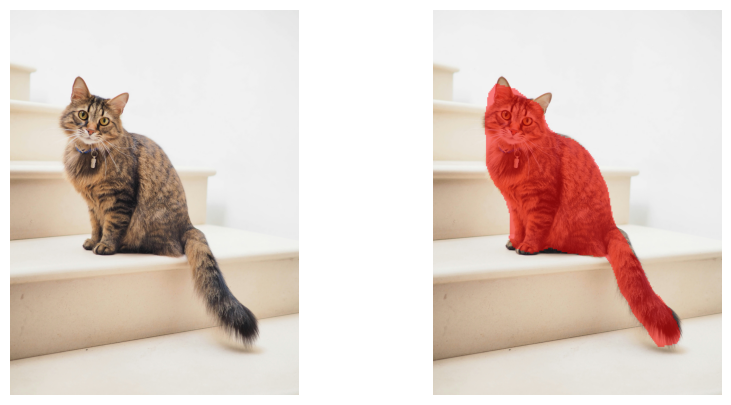

In [18]:
# === Penugasan: segmentasi foto sendiri (jalankan di Colab) ===
def segmentasi_foto(path, model=mdl, forward=fw, size=CFG["IMG"]):
    img = Image.open(path).convert("RGB")
    x = torch.from_numpy(np.array(img.resize((size, size), Image.BILINEAR))).permute(2, 0, 1).float() / 255
    x = ((x - MEAN) / STD).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        p = torch.sigmoid(forward(model, x))[0, 0].cpu().numpy()
    m = np.array(Image.fromarray((p > 0.5).astype(np.uint8) * 255).resize(img.size, Image.NEAREST)) > 0
    over = np.array(img).copy(); over[m] = (0.5 * over[m] + 0.5 * np.array([255, 0, 0])).astype(np.uint8)
    fig, ax = plt.subplots(1, 2, figsize=(10, 5)); ax[0].imshow(img); ax[1].imshow(over)
    for a in ax: a.axis("off")
    plt.show()
    return m

try:
    from google.colab import files
    up = files.upload()
    for nama in up:
        segmentasi_foto(nama)
except ImportError:
    print("Bukan di Colab: contoh memakai satu citra uji.")
    _ = segmentasi_foto(f"{ROOT}/images/{ID_TEST[0]}.jpg")